# MILK10k — Metadata + CNN Fusion (11-Class Training, Binary Validation)

**Primary configuration:** Only MetaData + CNN Fusion. This notebook does not train or compare the separate DualView or SingleView ensemble models.

**Inputs per lesion:** dermoscopic image + matched clinical close-up + `age_approx` + anatomical `site`  
**Image backbone:** shared-weight ConvNeXtV2 Tiny encoder (two visual views)  
**Metadata branch:** fold-fitted age imputation/normalization + learned categorical site embedding  
**Fusion:** concatenate both image embeddings with the metadata embedding, then classify 11 diagnoses  
**Image size:** **320 × 320** for both modalities  
**Training image batch size:** **8** (preserved from the source notebook)  
**Primary model-selection metric:** Binary (Benign vs Malignant) Balanced Accuracy

## Changes in this revision

- Keeps the same two image views, shared ConvNeXtV2 Tiny encoder, age/site metadata branch, 11-class cross-entropy objective, 320 image size, training image batch size of 8, gradient accumulation, AMP, EMA, and five-fold lesion-level evaluation.
- Makes regularization less restrictive for a controlled first experiment: dropout **0.20** (was 0.30), label smoothing **0.05** (was 0.10), and weight decay **0.02** (was 0.05).
- Uses AdamW parameter groups with no weight decay on biases, one-dimensional normalization parameters, or the site embedding.
- Reduces random erasing to 0.05 (dermoscopic) and 0.03 (clinical).
- Fits missing-age imputation, age scaling, and site vocabulary on each fold's training lesions only. No global age median is computed before splitting.
- Preserves image aspect ratio during evaluation (`Resize(short_edge)` + `CenterCrop`) instead of stretching images to a square.
- Adds binary sensitivity/specificity and 11-class OVR diagnostics to each fold, including fixed baseline top-4/top-6 groups rather than selecting the strongest classes from the test results.
- Uses a finer one-dimensional binary threshold search. Thresholds are fitted on each fold's validation data and aggregated for the independent held-out test set.
- Writes checkpoints and outputs to a **new v2 model directory** so they cannot be confused with checkpoints from the previous regularization settings.

## Important evaluation note

The model is trained on all 11 diagnoses. Binary validation metrics are computed by summing the 11 output probabilities into Benign and Malignant. The top-4/top-6 metrics are 11-class one-vs-rest balanced accuracies. They are separate metrics and should not be conflated.

The top-4 and top-6 diagnosis groups are fixed from the previously supplied first-column baseline: `NV`, `DF`, `BCC`, `SCCKA`, then `INF`, `VASC`. They are not reselected using held-out test performance.

A threshold selected on a fold's own validation labels is a calibration result for that fold, not an unbiased estimate of calibrated OOF performance. The independent held-out test set is not used for threshold fitting.

## Run order

1. Mount Google Drive if needed, then run imports/config, data download/unzip, label split, paired sample table, cache, dataset and model cells.
2. Set `cfg.fold_to_run` to 0–4 and run the fold-training cell. Repeat for all five folds in separate sessions or runs.
3. Run OOF evaluation after completing folds. Run held-out test evaluation only after all five folds are complete.

**Research use only. This notebook is not a clinically validated diagnostic system.**


In [ ]:
import os, math, time, copy, random, warnings, json, glob, re
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass

import numpy as np
import pandas as pd
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

@dataclass
class CFG:
    seed: int = 42
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    fold_to_run: int = 4           # change to 1, 2, 3, 4 for the remaining folds
    img_size: int = 320                 # increased from 256 to 320 for both views
    epochs: int = 20
    patience: int = 4
    warmup_epochs: int = 2
    freeze_epochs: int = 1
    batch_size: int = 8                 # preserved at 8 from the source notebook
    grad_accum_steps: int = 2           # unchanged; effective batch remains 16
    eval_batch_size: int = 8
    num_workers: int = 2
    cache_workers: int = 4
    head_lr: float = 2e-4
    base_lr: float = 3e-5
    min_lr_ratio: float = 0.02
    weight_decay: float = 0.02
    grad_clip: float = 1.0
    dropout: float = 0.20
    drop_path: float = 0.10
    label_smoothing: float = 0.05
    class_weight_power: float = 0.5
    # 0.0 disables group balancing; 0.5 applies a moderate shift toward equal total benign/malignant loss mass.
    binary_group_balance_strength: float = 0.5
    ema_decay: float = 0.996
    n_splits: int = 5
    test_size: float = 0.10
    backbone: str = 'convnextv2_tiny'
    use_grad_checkpointing: bool = True
    site_embedding_dim: int = 16
    metadata_hidden_dim: int = 128
    cache_max_side: int = 900
    n_bootstrap: int = 1000
    # Input data locations configured locally
    base: str = '/content/MILK10k_image_metadata_fusion'
    src_images_dir: str = '/content/MILK10k_Training_Input'
    metadata_csv: str = '/content/MILK10k_Training_Metadata.csv'
    groundtruth_csv: str = '/content/MILK10k_Training_GroundTruth.csv'

cfg = CFG()
DEVICE = cfg.device
CACHE_VERSION = 'dualview_320_metadata_age_site_v1'
CACHE_ROOT = os.path.join(cfg.base, 'cache', CACHE_VERSION)
DERM_CACHE_DIR = os.path.join(CACHE_ROOT, 'dermoscopic')
CLIN_CACHE_DIR = os.path.join(CACHE_ROOT, 'clinical')
MODEL_DIR = os.path.join(cfg.base, 'models_image_metadata_fusion_11class_binary_eval_320_reg_v2')

for directory in [cfg.base, CACHE_ROOT, DERM_CACHE_DIR, CLIN_CACHE_DIR, MODEL_DIR,
                  os.path.join(cfg.base, 'logs')]:
    os.makedirs(directory, exist_ok=True)

print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available() and torch.cuda.get_device_properties(0).total_memory < 12 * (1024 ** 3):
    print('Low-VRAM GPU detected (<12 GiB). Training image batch_size remains fixed at 8 as requested;')
    print('AMP and gradient checkpointing remain enabled. A CUDA OOM would require a manual batch-size change.')

print(f'Device: {DEVICE} | fold: {cfg.fold_to_run}/{cfg.n_splits - 1}')
print(f'Image size: {cfg.img_size} x {cfg.img_size} | batch: {cfg.batch_size} | '
      f'accumulation: {cfg.grad_accum_steps} | effective batch: {cfg.batch_size * cfg.grad_accum_steps}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | VRAM: {props.total_memory / (1024**3):.1f} GiB')
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
print('Cache:', CACHE_ROOT)
print('Models:', MODEL_DIR)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed + cfg.fold_to_run)

PyTorch: 2.14.1+cu130 | CUDA available: True
Device: cuda | fold: 4/4
Image size: 320 x 320 | batch: 8 | accumulation: 2 | effective batch: 16
GPU: Tesla T4 | VRAM: 14.6 GiB
Cache: /content/MILK10k_image_metadata_fusion/cache/dualview_320_metadata_age_site_v1
Models: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2


In [ ]:
# %% 3 — Download data (skip if files already in /content — Colab wipes /content on disconnect, Drive does NOT)
need = not (os.path.exists(cfg.groundtruth_csv) and os.path.exists(cfg.metadata_csv) and os.path.isdir(cfg.src_images_dir))
if need:
    print('Downloading (first session only)...')
    get_ipython().system('gdown --id 1keRWrLIpi6lFiV-KsSoMrI-T-Qy9fd_y')
    get_ipython().system('gdown --id 1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6')
    get_ipython().system('gdown --id 1EmRfhgtfaqJqhrHNF7A9V0JigZpsv7rd')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1keRWrLIpi6lFiV-KsSoMrI-T-Qy9fd_y
To: /content/MILK10k_Training_GroundTruth.csv
100% 294k/294k [00:00<00:00, 34.5MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6
From (redirected): https://drive.google.com/uc?id=1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6&confirm=t&uuid=b341c4f1-1506-4f4e-97f9-0c91feea13a4
To: /content/MILK10k_Training_Input.zip
100% 329M/329M [00:03<00:00, 101MB/s] 
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarnin

In [ ]:
!unzip -q /content/MILK10k_Training_Input.zip

In [ ]:
# %% 4 — Original 11 labels + binary mapping + lesion-level held-out TEST split
import re
df = pd.read_csv(cfg.groundtruth_csv)
meta_raw = pd.read_csv(cfg.metadata_csv)

# Helper to resolve metadata column names
def resolve_column(frame, candidates, feature_name):
    lookup = {str(col).strip().lower(): col for col in frame.columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    raise KeyError(f'Could not identify {feature_name} metadata column.')

AGE_META_COL = resolve_column(meta_raw, ['age_approx', 'age', 'age_approx_years', 'age_approx_5year'], 'age_approx')
SITE_META_COL = resolve_column(meta_raw, ['site', 'anatomic_site', 'anatomical_site', 'anatom_site_general', 'site_name'], 'site')

def parse_age_approx(value):
    if pd.isna(value):
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        numbers = re.findall(r'\d+(?:\.\d+)?', str(value))
        if len(numbers) >= 2 and ('-' in str(value) or 'to' in str(value).lower()):
            return (float(numbers[0]) + float(numbers[1])) / 2.0
        if numbers:
            return float(numbers[0])
        return np.nan

def clean_site_value(value):
    if pd.isna(value) or str(value).strip() == '':
        return 'Unknown'
    return re.sub(r'\s+', ' ', str(value).strip().lower().replace('_', ' ')).title()

# Group raw metadata to lesion level (by taking first available non-null or using fallback)
meta_raw['parsed_age'] = meta_raw[AGE_META_COL].apply(parse_age_approx)
meta_raw['cleaned_site'] = meta_raw[SITE_META_COL].apply(clean_site_value)

# Do not impute age here. The median is fitted inside each fold's MetadataPreprocessor
# using only that fold's training lesions, then reused for validation and test.

# Collapse metadata to lesion-level to merge into ground truth
lesion_meta = meta_raw.groupby('lesion_id').agg({
    'parsed_age': 'first',
    'cleaned_site': 'first'
}).reset_index()

# Merge imputed features directly into main dataframe
df['lesion_id'] = df['lesion_id'].astype(str)
lesion_meta['lesion_id'] = lesion_meta['lesion_id'].astype(str)
df = df.merge(lesion_meta, on='lesion_id', how='left')

# Site is categorical and can safely map missing values to the explicit Unknown category.
# Age NaNs are intentionally retained until the per-fold training-only imputer is fitted.
df['cleaned_site'] = df['cleaned_site'].fillna('Unknown')

CLASSES = ['AKIEC','BCC','BEN_OTH','BKL','DF','INF','MAL_OTH','MEL','NV','SCCKA','VASC']
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}

# Fixed diagnostic groups chosen from the previously reported primary-configuration baseline.
FIXED_TOP4_CLASSES = ['NV', 'DF', 'BCC', 'SCCKA']
FIXED_TOP6_CLASSES = FIXED_TOP4_CLASSES + ['INF', 'VASC']

BENIGN_DIAGNOSES = ['BKL','NV','DF','BEN_OTH','INF','VASC']
MALIGNANT_DIAGNOSES = ['MEL','BCC','SCCKA','AKIEC','MAL_OTH']
BINARY_CLASSES = ['Benign', 'Malignant']
BINARY_CLASS_TO_IDX = {name: idx for idx, name in enumerate(BINARY_CLASSES)}
CLASS_TO_BINARY = {name: 'Benign' for name in BENIGN_DIAGNOSES}
CLASS_TO_BINARY.update({name: 'Malignant' for name in MALIGNANT_DIAGNOSES})

df['class_label'] = df[CLASSES].apply(lambda row: next((name for name in CLASSES if row[name] == 1), 'UNKNOWN'), axis=1)
df['binary_class'] = df['class_label'].map(CLASS_TO_BINARY)
df['binary_label'] = df['binary_class'].map(BINARY_CLASS_TO_IDX).astype(int)

outer_stratify_col = 'class_label'
trainval_lesions, test_lesions = train_test_split(
    df, test_size=cfg.test_size, random_state=cfg.seed, stratify=df[outer_stratify_col]
)
trainval_lesions = trainval_lesions.reset_index(drop=True)
test_lesions = test_lesions.reset_index(drop=True)

print(f'Train+Val: {len(trainval_lesions)} lesions | Test: {len(test_lesions)} lesions')

Train+Val: 4716 lesions | Test: 524 lesions


In [ ]:
# %% 5 — Build lesion-matched image pairs using already imputed age and site
meta = pd.read_csv(cfg.metadata_csv)
meta['isic_id'] = meta['isic_id'].astype(str)
meta['image_type_norm'] = meta['image_type'].astype(str).str.strip().str.lower()
type_map = dict(zip(meta['isic_id'], meta['image_type_norm']))

IMAGE_EXTS = ('.jpg', '.jpeg', '.png')

def classify_image_type(image_type):
    value = str(image_type).lower().replace('_', ' ').replace('-', ' ')
    if 'dermoscop' in value:
        return 'dermoscopic'
    if 'clinical' in value or 'close up' in value or 'closeup' in value:
        return 'clinical'
    return 'other'

def build_sample_table(lesion_df, split_name):
    rows, missing_folder, missing_view = [], [], []
    for _, lesion in lesion_df.iterrows():
        lesion_id = str(lesion['lesion_id'])
        diagnosis = lesion['class_label']
        folder = os.path.join(cfg.src_images_dir, lesion_id)
        if not os.path.isdir(folder):
            missing_folder.append(lesion_id)
            continue

        derm_candidates, clinical_candidates = [], []
        for filename in sorted(os.listdir(folder)):
            if not filename.lower().endswith(IMAGE_EXTS):
                continue
            image_id = os.path.splitext(filename)[0]
            view = classify_image_type(type_map.get(image_id, 'unknown'))
            full_path = os.path.join(folder, filename)
            if view == 'dermoscopic':
                derm_candidates.append((image_id, full_path))
            elif view == 'clinical':
                clinical_candidates.append((image_id, full_path))

        if len(derm_candidates) != 1 or len(clinical_candidates) != 1:
            missing_view.append((lesion_id, len(derm_candidates), len(clinical_candidates)))
            continue

        derm_id, derm_path = derm_candidates[0]
        clinical_id, clinical_path = clinical_candidates[0]
        binary_class = CLASS_TO_BINARY[diagnosis]

        rows.append({
            'lesion_id': lesion_id,
            'isic_id': derm_id,
            'clinical_isic_id': clinical_id,
            'split': split_name,
            'derm_src_path': derm_path,
            'clinical_src_path': clinical_path,
            'derm_cache_path': os.path.join(DERM_CACHE_DIR, derm_id + '.jpg'),
            'clinical_cache_path': os.path.join(CLIN_CACHE_DIR, clinical_id + '.jpg'),
            'label': CLASS_TO_IDX[diagnosis],
            'class_label': diagnosis,
            'binary_label': BINARY_CLASS_TO_IDX[binary_class],
            'binary_class': binary_class,
            'age_approx': lesion['parsed_age'],
            'site': lesion['cleaned_site'],
        })
    return pd.DataFrame(rows).reset_index(drop=True)

test_samples = build_sample_table(test_lesions, 'test')
trainval_samples_all = build_sample_table(trainval_lesions, 'trainval')

In [ ]:
# %% 6 — Modality-specific preprocessing + 320-resolution paired image cache

def crop_dark_borders(img_np, threshold=12):
    """Remove only obvious dark outer borders, not the clinical/lesion field."""
    if img_np.ndim != 3 or img_np.shape[2] != 3:
        return img_np
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    mask = (gray > threshold).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img_np
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    H, W = img_np.shape[:2]
    if w >= 0.50 * W and h >= 0.50 * H:
        return img_np[y:y+h, x:x+w]
    return img_np


def _clahe_luminance(img_np, clip_limit=2.0):
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(8, 8))
    l_channel = clahe.apply(l_channel)
    return cv2.cvtColor(cv2.merge((l_channel, a_channel, b_channel)), cv2.COLOR_LAB2RGB)


def preprocess_derm_np(img_np):
    """Dermoscopic-only: conservative border crop, hair inpainting, fixed luminance CLAHE."""
    img_np = np.ascontiguousarray(crop_dark_borders(img_np))
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    inpainted = cv2.inpaint(img_np, hair_mask, 1, cv2.INPAINT_TELEA)
    return _clahe_luminance(inpainted, clip_limit=1.9)


def preprocess_clinical_np(img_np):
    """Clinical close-up: gentle border crop and mild luminance CLAHE; retain hair/context."""
    img_np = np.ascontiguousarray(crop_dark_borders(img_np))
    return _clahe_luminance(img_np, clip_limit=1.5)


def _resize_max_side(img, max_side):
    width, height = img.size
    scale = min(1.0, float(max_side) / max(width, height))
    if scale < 1.0:
        img = img.resize((max(1, round(width * scale)), max(1, round(height * scale))), Image.Resampling.LANCZOS)
    return img


def _cache_one(job):
    src_path, dst_path, modality = job
    if os.path.exists(dst_path):
        return None
    try:
        with Image.open(src_path) as image:
            img_np = np.asarray(image.convert('RGB'))
        if modality == 'dermoscopic':
            processed = preprocess_derm_np(img_np)
        elif modality == 'clinical':
            processed = preprocess_clinical_np(img_np)
        else:
            raise ValueError(f'Unknown modality: {modality}')
        output = _resize_max_side(Image.fromarray(processed), cfg.cache_max_side)
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)
        output.save(dst_path, format='JPEG', quality=94, optimize=True)
        return None
    except Exception as exc:
        return (src_path, repr(exc))


def build_pair_cache(samples):
    jobs = []
    for row in samples.itertuples(index=False):
        jobs.append((row.derm_src_path, row.derm_cache_path, 'dermoscopic'))
        jobs.append((row.clinical_src_path, row.clinical_cache_path, 'clinical'))
    missing_jobs = [job for job in jobs if not os.path.exists(job[1])]
    if not missing_jobs:
        print(f'Paired cache already complete: {len(jobs)} images.')
        return
    print(f'Building {len(missing_jobs)} cache files ({len(jobs)} total paired views)...')
    cv2.setNumThreads(1)
    workers = max(1, min(cfg.cache_workers, os.cpu_count() or 1))
    with ThreadPoolExecutor(max_workers=workers) as pool:
        results = list(tqdm(pool.map(_cache_one, missing_jobs), total=len(missing_jobs), desc='preprocessing'))
    failures = [result for result in results if result is not None]
    print(f'Cache created: {len(missing_jobs) - len(failures)} | failed: {len(failures)}')
    if failures:
        print('First failures:', failures[:10])
        raise RuntimeError('Some images failed preprocessing; fix these before training.')

all_samples = pd.concat([trainval_samples_all, test_samples], ignore_index=True)
build_pair_cache(all_samples)
assert all(os.path.exists(path) for path in all_samples['derm_cache_path']), 'Some dermoscopic cache files are missing.'
assert all(os.path.exists(path) for path in all_samples['clinical_cache_path']), 'Some clinical cache files are missing.'
print('All paired image cache files are available.')

Building 10480 cache files (10480 total paired views)...


preprocessing:   0%|          | 0/10480 [00:00<?, ?it/s]

Cache created: 10480 | failed: 0
All paired image cache files are available.


In [ ]:
# %% 7 — 320 x 320 paired Dataset + fold-fitted age/site preprocessing
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
S = cfg.img_size

derm_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.82, 1.0), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.25),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.08, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.05, scale=(0.02, 0.06)),
])
clinical_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.85, 1.0), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.005),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.03, scale=(0.02, 0.05)),
])

def make_eval_tf(horizontal_flip=False, vertical_flip=False):
    # Resize preserves aspect ratio; CenterCrop gives the fixed S x S encoder input.
    ops = [transforms.Resize(S), transforms.CenterCrop(S)]
    if horizontal_flip:
        ops.append(transforms.Lambda(lambda image: transforms.functional.hflip(image)))
    if vertical_flip:
        ops.append(transforms.Lambda(lambda image: transforms.functional.vflip(image)))
    ops.extend([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops)

val_tf = make_eval_tf()
tta_pairs = [
    (val_tf, val_tf),
    (make_eval_tf(horizontal_flip=True), make_eval_tf(horizontal_flip=True)),
    (make_eval_tf(vertical_flip=True), make_eval_tf(vertical_flip=True)),
]

class MetadataPreprocessor:
    """Fits age imputation/scaling and site IDs on the current fold's training lesions only."""
    def __init__(self):
        self.fitted = False
        self.age_median = None
        self.age_mean = None
        self.age_std = None
        self.site_vocab = {}

    def fit(self, samples):
        ages = samples['age_approx'].to_numpy(dtype=np.float32)
        finite_ages = ages[np.isfinite(ages)]
        if finite_ages.size == 0:
            raise ValueError('No non-missing age values found in this fold training set.')
        self.age_median = float(np.median(finite_ages))
        ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
        self.age_mean = float(np.mean(ages))
        age_std = float(np.std(ages))
        self.age_std = age_std if age_std > 1e-6 else 1.0

        categories = sorted(set(samples['site'].fillna('Unknown').astype(str).tolist()))
        if 'Unknown' not in categories:
            categories.append('Unknown')
        self.site_vocab = {val: idx for idx, val in enumerate(categories)}
        self.fitted = True
        return self

    @property
    def num_site_categories(self):
        return len(self.site_vocab)

    def transform(self, samples):
        ages = samples['age_approx'].to_numpy(dtype=np.float32)
        ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
        ages = ((ages - self.age_mean) / self.age_std).astype(np.float32)
        sites = samples['site'].fillna('Unknown').astype(str).tolist()
        site_ids = np.asarray([self.site_vocab.get(val, self.site_vocab.get('Unknown', 0)) for val in sites], dtype=np.int64)
        return ages, site_ids

    def state_dict(self):
        return {
            'age_median': self.age_median,
            'age_mean': self.age_mean,
            'age_std': self.age_std,
            'site_vocab': self.site_vocab
        }

    @classmethod
    def from_state_dict(cls, state):
        obj = cls()
        obj.age_median = float(state['age_median'])
        obj.age_mean = float(state['age_mean'])
        obj.age_std = float(state['age_std'])
        obj.site_vocab = state['site_vocab']
        obj.fitted = True
        return obj

class PairedLesionDataset(Dataset):
    def __init__(self, samples, derm_transform, clinical_transform, metadata_preprocessor):
        self.derm_paths = samples['derm_cache_path'].tolist()
        self.clinical_paths = samples['clinical_cache_path'].tolist()
        self.labels = samples['label'].astype(int).tolist()
        self.derm_transform = derm_transform
        self.clinical_transform = clinical_transform
        self.ages, self.site_ids = metadata_preprocessor.transform(samples)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        with Image.open(self.derm_paths[index]) as image:
            derm = self.derm_transform(image.convert('RGB'))
        with Image.open(self.clinical_paths[index]) as image:
            clinical = self.clinical_transform(image.convert('RGB'))
        age = torch.tensor(self.ages[index], dtype=torch.float32)
        site = torch.tensor(self.site_ids[index], dtype=torch.long)
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return derm, clinical, age, site, label

In [ ]:
# %% 8 — Dual-image + metadata ConvNeXtV2 fusion model and evaluation helpers
try:
    import timm
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm'])
    import timm


class DualImageMetadataConvNeXtV2(nn.Module):
    """Shared visual encoder + age/site metadata branch + late feature fusion."""
    def __init__(self, num_classes, num_site_categories, model_name='convnextv2_tiny', pretrained=True):
        super().__init__()
        self.encoder = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=0,
            global_pool='avg',
            drop_path_rate=cfg.drop_path,
        )
        self.gradient_checkpointing_enabled = False
        if cfg.use_grad_checkpointing and hasattr(self.encoder, 'set_grad_checkpointing'):
            self.encoder.set_grad_checkpointing(True)
            self.gradient_checkpointing_enabled = True

        feature_dim = self.encoder.num_features
        self.site_embedding = nn.Embedding(max(1, int(num_site_categories)), cfg.site_embedding_dim)
        metadata_input_dim = 1 + cfg.site_embedding_dim
        self.metadata_encoder = nn.Sequential(
            nn.Linear(metadata_input_dim, cfg.metadata_hidden_dim),
            nn.LayerNorm(cfg.metadata_hidden_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
        )
        fused_dim = feature_dim * 2 + cfg.metadata_hidden_dim
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(cfg.dropout),
            nn.Linear(fused_dim, feature_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(feature_dim, num_classes),
        )

    def forward(self, dermoscopic_image, clinical_image, age, site):
        if dermoscopic_image.shape != clinical_image.shape:
            raise ValueError(
                f'Image inputs must have matching shapes; got {tuple(dermoscopic_image.shape)} '
                f'and {tuple(clinical_image.shape)}'
            )
        batch_size = dermoscopic_image.shape[0]
        # One shared-weight encoder call over the combined 2B batch of image views.
        both_views = torch.cat([dermoscopic_image, clinical_image], dim=0)
        features = self.encoder(both_views)
        derm_features = features[:batch_size]
        clinical_features = features[batch_size:]
        image_features = torch.cat([derm_features, clinical_features], dim=1)

        age = age.float().reshape(-1, 1)
        site = site.long().reshape(-1)
        site_features = self.site_embedding(site)
        metadata_features = self.metadata_encoder(torch.cat([age, site_features], dim=1))
        fused = torch.cat([image_features, metadata_features], dim=1)
        return self.classifier(fused)


def make_class_weights(labels, power, binary_group_balance_strength=0.0):
    """Inverse-frequency 11-class weights, optionally nudged toward equal binary-group loss mass."""
    counts = np.bincount(np.asarray(labels), minlength=NUM_CLASSES).astype(float)
    if np.any(counts == 0):
        missing = [CLASSES[idx] for idx, count in enumerate(counts) if count == 0]
        raise ValueError(f'Training fold is missing diagnoses: {missing}')
    weights = 1.0 / (counts ** power)
    weights = weights / (weights * counts).sum() * counts.sum()

    strength = float(np.clip(binary_group_balance_strength, 0.0, 1.0))
    if strength > 0:
        benign_idx = np.asarray([CLASS_TO_IDX[c] for c in BENIGN_DIAGNOSES], dtype=int)
        malignant_idx = np.asarray([CLASS_TO_IDX[c] for c in MALIGNANT_DIAGNOSES], dtype=int)
        benign_mass = float(np.sum(weights[benign_idx] * counts[benign_idx]))
        malignant_mass = float(np.sum(weights[malignant_idx] * counts[malignant_idx]))
        total_mass = benign_mass + malignant_mass
        benign_factor = total_mass / (2.0 * max(benign_mass, 1e-12))
        malignant_factor = total_mass / (2.0 * max(malignant_mass, 1e-12))
        weights[benign_idx] *= benign_factor ** strength
        weights[malignant_idx] *= malignant_factor ** strength
        # Preserve the same overall mean sample weight after group adjustment.
        weights = weights / max(float(np.sum(weights * counts) / counts.sum()), 1e-12)
    return torch.tensor(weights, dtype=torch.float32), counts


def compute_11class_ovr_metrics(probs_11, y_true_11):
    """Macro and fixed subset OVR balanced accuracy; absent classes are reported as NaN."""
    y_true_11 = np.asarray(y_true_11, dtype=np.int64)
    y_pred_11 = np.asarray(probs_11).argmax(1)
    scores = {}
    for class_idx, class_name in enumerate(CLASSES):
        truth = (y_true_11 == class_idx).astype(int)
        prediction = (y_pred_11 == class_idx).astype(int)
        scores[class_name] = (float(balanced_accuracy_score(truth, prediction))
                              if truth.sum() > 0 and truth.sum() < len(truth) else float('nan'))

    finite_scores = [value for value in scores.values() if np.isfinite(value)]
    macro_ovr = float(np.mean(finite_scores)) if finite_scores else float('nan')
    top4_values = [scores[name] for name in FIXED_TOP4_CLASSES if np.isfinite(scores.get(name, np.nan))]
    top6_values = [scores[name] for name in FIXED_TOP6_CLASSES if np.isfinite(scores.get(name, np.nan))]
    top4 = float(np.mean(top4_values)) if top4_values else float('nan')
    top6 = float(np.mean(top6_values)) if top6_values else float('nan')
    return scores, macro_ovr, top4, top6


def lr_factor(step, warmup_steps, total_steps, min_ratio):
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * progress))


class ModelEMA:
    def __init__(self, model, decay=0.996):
        self.module = copy.deepcopy(model).eval()
        for parameter in self.module.parameters():
            parameter.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        decay = min(self.decay, (1 + self.updates) / (10 + self.updates))
        model_state = model.state_dict()
        for key, value in self.module.state_dict().items():
            if value.dtype.is_floating_point:
                value.mul_(decay).add_(model_state[key].detach(), alpha=1 - decay)
            else:
                value.copy_(model_state[key])


@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probabilities = []
    for derm, clinical, age, site, _labels in loader:
        derm = derm.to(DEVICE, non_blocking=True)
        clinical = clinical.to(DEVICE, non_blocking=True)
        age = age.to(DEVICE, non_blocking=True)
        site = site.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
            logits = model(derm, clinical, age, site)
        probabilities.append(logits.float().softmax(1).cpu())
    return torch.cat(probabilities).numpy()


@torch.no_grad()
def predict_probs_tta(model, samples, metadata_preprocessor, label_col='label', batch_size=None):
    all_probs = np.zeros((len(samples), NUM_CLASSES), dtype=np.float32)
    labels = samples[label_col].to_numpy(dtype=np.int64)
    batch_size = batch_size or cfg.eval_batch_size
    for derm_tf, clinical_tf in tta_pairs:
        dataset = PairedLesionDataset(samples, derm_tf, clinical_tf, metadata_preprocessor)
        loader = DataLoader(
            dataset, batch_size=batch_size, shuffle=False,
            num_workers=cfg.num_workers, pin_memory=(DEVICE == 'cuda'),
            persistent_workers=(cfg.num_workers > 0)
        )
        all_probs += predict_probs(model, loader)
    return all_probs / len(tta_pairs), labels


def aggregate_11class_probs_to_binary(probs_11):
    probs_binary = np.zeros((len(probs_11), len(BINARY_CLASSES)), dtype=np.float32)
    for class_idx, diagnosis in enumerate(CLASSES):
        binary_idx = BINARY_CLASS_TO_IDX[CLASS_TO_BINARY[diagnosis]]
        probs_binary[:, binary_idx] += probs_11[:, class_idx]
    return probs_binary


def tune_thresholds(val_probs, val_y):
    """Fine one-dimensional threshold search for the Benign probability (class index 0)."""
    val_probs = np.asarray(val_probs, dtype=np.float64)
    val_y = np.asarray(val_y, dtype=np.int64)
    p_benign = val_probs[:, 0]
    candidates = np.linspace(0.20, 0.80, 1201)
    scores = np.empty(len(candidates), dtype=np.float64)

    for index, threshold in enumerate(candidates):
        predictions = np.where(p_benign >= threshold, 0, 1)
        scores[index] = balanced_accuracy_score(val_y, predictions)

    best_score = float(np.max(scores))
    best_indices = np.flatnonzero(np.isclose(scores, best_score))
    # Stable tie-break: prefer the threshold closest to the neutral 0.50 decision boundary.
    best_index = best_indices[np.argmin(np.abs(candidates[best_indices] - 0.50))]
    best_threshold = float(candidates[best_index])
    # The existing downstream weighted-argmax interface is retained.
    weights = np.asarray([1.0 - best_threshold, best_threshold], dtype=np.float32)
    return weights, best_score


def bootstrap_bal_acc(y, pred, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    y, pred = np.asarray(y), np.asarray(pred)
    scores = []
    for _ in range(n):
        indices = rng.integers(0, len(y), len(y))
        if len(np.unique(y[indices])) < len(BINARY_CLASSES):
            continue
        scores.append(balanced_accuracy_score(y[indices], pred[indices]))
    if not scores:
        score = balanced_accuracy_score(y, pred)
        return float(score), float('nan'), float('nan')
    return float(np.mean(scores)), float(np.percentile(scores, 2.5)), float(np.percentile(scores, 97.5))


def report_binary(y, pred, name):
    labels = np.arange(len(BINARY_CLASSES))
    score, low, high = bootstrap_bal_acc(y, pred, n=cfg.n_bootstrap)
    print(f'\n=== {name} === Binary Bal-Acc {score:.4f} | 95% CI [{low:.4f}, {high:.4f}] | n={len(y)}')
    print(classification_report(
        y, pred, labels=labels, target_names=BINARY_CLASSES, digits=3, zero_division=0
    ))
    print('Confusion matrix (rows=true; Benign, Malignant):')
    print(confusion_matrix(y, pred, labels=labels))
    return score, low, high

print('Dual-image + age/site metadata fusion model is ready.')

Dual-image + age/site metadata fusion model is ready.


In [ ]:
# %% 9 — Train one fold (weighted CE, AMP, gradient accumulation, EMA)

def train_one_fold(train_samples, val_samples, fold):
    fold_tag = f'fold{fold}'
    best_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_best.pt')
    last_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_last.pt')
    hist_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_hist.json')
    meta_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_preprocessor.json')

    # Fit all metadata transforms strictly on this fold's training lesions.
    metadata_preprocessor = MetadataPreprocessor().fit(train_samples)
    with open(meta_path, 'w') as file:
        json.dump(metadata_preprocessor.state_dict(), file, indent=2)

    train_ds = PairedLesionDataset(
        train_samples, derm_train_tf, clinical_train_tf, metadata_preprocessor
    )
    loader_kwargs = dict(
        num_workers=cfg.num_workers,
        pin_memory=(DEVICE == 'cuda'),
        persistent_workers=(cfg.num_workers > 0),
    )
    train_loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, shuffle=True,
        drop_last=False, **loader_kwargs
    )
    updates_per_epoch = math.ceil(len(train_loader) / cfg.grad_accum_steps)
    if updates_per_epoch < 1:
        raise ValueError('Training fold has no batches. Reduce batch_size or inspect the paired sample table.')

    model = DualImageMetadataConvNeXtV2(
        NUM_CLASSES,
        num_site_categories=metadata_preprocessor.num_site_categories,
        model_name=cfg.backbone,
        pretrained=True,
    ).to(DEVICE)
    print('Gradient checkpointing active:', model.gradient_checkpointing_enabled)
    ema = ModelEMA(model, cfg.ema_decay)

    metadata_head_prefixes = ('classifier', 'site_embedding', 'metadata_encoder')
    parameter_groups = {
        'backbone_decay': [], 'backbone_no_decay': [],
        'head_decay': [], 'head_no_decay': [],
    }
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        is_head = name.startswith(metadata_head_prefixes)
        # Biases, 1-D norm parameters, and the categorical embedding are excluded from weight decay.
        no_decay = name.endswith('.bias') or parameter.ndim <= 1 or name.startswith('site_embedding')
        key = ('head_' if is_head else 'backbone_') + ('no_decay' if no_decay else 'decay')
        parameter_groups[key].append(parameter)

    optimizer_groups = []
    for key, params in parameter_groups.items():
        if not params:
            continue
        is_head = key.startswith('head_')
        no_decay = key.endswith('no_decay')
        optimizer_groups.append({
            'params': params,
            'lr': cfg.head_lr if is_head else cfg.base_lr,
            'weight_decay': 0.0 if no_decay else cfg.weight_decay,
        })

    optimizer = torch.optim.AdamW(
        optimizer_groups,
        betas=(0.9, 0.999), eps=1e-8
    )
    total_updates = cfg.epochs * updates_per_epoch
    warmup_updates = cfg.warmup_epochs * updates_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: lr_factor(step, warmup_updates, total_updates, cfg.min_lr_ratio)
    )
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
    class_weights, counts = make_class_weights(
        train_ds.labels, cfg.class_weight_power, cfg.binary_group_balance_strength
    )
    class_weights = class_weights.to(DEVICE)
    print(f'[fold {fold}] training lesion counts:', dict(zip(CLASSES, counts.astype(int))))
    print(f'[fold {fold}] binary group-balance strength: {cfg.binary_group_balance_strength:.2f}')
    print(f'[fold {fold}] weighted CE:', {
        name: round(float(weight), 3) for name, weight in zip(CLASSES, class_weights.detach().cpu())
    })

    start_epoch, best, best_epoch, bad = 0, -1.0, -1, 0
    history = {key: [] for key in ['train_loss', 'train_bal_acc_11', 'val_binary_nll', 'val_bal_acc_binary',
                                      'val_benign_sensitivity', 'val_malignant_sensitivity',
                                      'val_11_macro_ovr', 'val_11_fixed_top4', 'val_11_fixed_top6']}
    if os.path.exists(last_path):
        checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model'])
        ema.module.load_state_dict(checkpoint['ema'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scheduler.load_state_dict(checkpoint['scheduler'])
        if 'scaler' in checkpoint:
            scaler.load_state_dict(checkpoint['scaler'])
        start_epoch = checkpoint['epoch'] + 1
        best, best_epoch, bad = checkpoint['best'], checkpoint['best_epoch'], checkpoint['bad']
        history = checkpoint['history']
        print(f'>>> Resuming fold {fold} at epoch {start_epoch}; best binary Bal-Acc {best:.4f}.')
    elif os.path.exists(best_path):
        print('Best checkpoint exists without a last checkpoint; starting a fresh run for this fold.')

    def set_backbone_trainable(flag):
        for name, parameter in model.named_parameters():
            is_metadata_or_classification_head = name.startswith(metadata_head_prefixes)
            parameter.requires_grad_(flag or is_metadata_or_classification_head)

    optimizer.zero_grad(set_to_none=True)
    start_time = time.time()
    for epoch in range(start_epoch, cfg.epochs):
        set_backbone_trainable(epoch >= cfg.freeze_epochs)
        model.train()
        losses, train_preds, train_true = [], [], []
        optimizer.zero_grad(set_to_none=True)

        for step, (derm, clinical, age, site, labels) in enumerate(
            tqdm(train_loader, desc=f'Fold {fold} | Epoch {epoch + 1}', leave=False)
        ):
            derm = derm.to(DEVICE, non_blocking=True)
            clinical = clinical.to(DEVICE, non_blocking=True)
            age = age.to(DEVICE, non_blocking=True)
            site = site.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
                logits = model(derm, clinical, age, site)
                loss = F.cross_entropy(
                    logits.float(), labels, weight=class_weights,
                    label_smoothing=cfg.label_smoothing
                )
                group_start = (step // cfg.grad_accum_steps) * cfg.grad_accum_steps
                current_group_size = min(cfg.grad_accum_steps, len(train_loader) - group_start)
                scaled_loss = loss / current_group_size

            scaler.scale(scaled_loss).backward()
            is_update_step = ((step + 1) % cfg.grad_accum_steps == 0) or ((step + 1) == len(train_loader))
            if is_update_step:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                ema.update(model)

            losses.append(float(loss.detach().cpu()))
            train_preds.append(logits.detach().argmax(1).cpu())
            train_true.append(labels.detach().cpu())

        val_probs_11, val_y_binary = predict_probs_tta(
            ema.module, val_samples, metadata_preprocessor, label_col='binary_label'
        )
        val_probs_binary = aggregate_11class_probs_to_binary(val_probs_11)
        val_pred_binary = val_probs_binary.argmax(1)
        selected_p = val_probs_binary[np.arange(len(val_y_binary)), val_y_binary]
        val_nll = float(-np.log(np.clip(selected_p, 1e-8, 1.0)).mean())
        train_bal = float(balanced_accuracy_score(
            torch.cat(train_true).numpy(), torch.cat(train_preds).numpy()
        ))
        val_bal = float(balanced_accuracy_score(val_y_binary, val_pred_binary))
        val_cm = confusion_matrix(val_y_binary, val_pred_binary, labels=np.arange(2))
        val_recalls = np.divide(
            np.diag(val_cm), val_cm.sum(axis=1),
            out=np.zeros(2, dtype=float), where=val_cm.sum(axis=1) > 0
        )
        _class_scores, val_macro_11, val_top4_11, val_top6_11 = compute_11class_ovr_metrics(
            val_probs_11, val_samples['label'].to_numpy(dtype=np.int64)
        )

        history['train_loss'].append(float(np.mean(losses)))
        history['train_bal_acc_11'].append(train_bal)
        history['val_binary_nll'].append(val_nll)
        history['val_bal_acc_binary'].append(val_bal)
        history['val_benign_sensitivity'].append(float(val_recalls[0]))
        history['val_malignant_sensitivity'].append(float(val_recalls[1]))
        history['val_11_macro_ovr'].append(val_macro_11)
        history['val_11_fixed_top4'].append(val_top4_11)
        history['val_11_fixed_top6'].append(val_top6_11)

        improved = val_bal > best
        if improved:
            best, best_epoch, bad = val_bal, epoch, 0
            torch.save(ema.module.state_dict(), best_path)
        else:
            bad += 1

        elapsed = time.time() - start_time
        peak_vram = (torch.cuda.max_memory_allocated() / (1024 ** 3)) if DEVICE == 'cuda' else 0.0
        print(
            f'fold {fold} | epoch {epoch + 1:02d}/{cfg.epochs} '
            f'| lr {optimizer.param_groups[0]["lr"]:.2e} '
            f'| train loss {np.mean(losses):.3f} / train 11c BalAcc {train_bal:.3f} '
            f'| val binary NLL {val_nll:.3f} / BalAcc {val_bal:.3f} '
            f'(Benign sens {val_recalls[0]:.3f}, Malignant sens {val_recalls[1]:.3f}) '
            f'| val 11c macro/top4/top6 {val_macro_11:.3f}/{val_top4_11:.3f}/{val_top6_11:.3f} '
            f'| peak VRAM {peak_vram:.2f} GiB {"*" if improved else ""} | {elapsed:.0f}s'
        )

        torch.save({
            'model': model.state_dict(), 'ema': ema.module.state_dict(),
            'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(), 'epoch': epoch,
            'best': best, 'best_epoch': best_epoch, 'bad': bad, 'history': history,
        }, last_path)
        with open(hist_path, 'w') as file:
            json.dump(history, file)

        if bad >= cfg.patience:
            print(f'Early stopping fold {fold}; best binary Bal-Acc {best:.4f} at epoch {best_epoch + 1}.')
            break

    if not os.path.exists(best_path):
        raise RuntimeError(f'No best checkpoint was produced for fold {fold}.')
    ema.module.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))
    return ema.module, history, best, best_epoch, best_path, metadata_preprocessor, meta_path

Fold 4: 3773 paired training lesions | 943 validation lesions
Gradient checkpointing active: True
[fold 4] training lesion counts: {'AKIEC': np.int64(219), 'BCC': np.int64(1816), 'BEN_OTH': np.int64(32), 'BKL': np.int64(391), 'DF': np.int64(38), 'INF': np.int64(36), 'MAL_OTH': np.int64(6), 'MEL': np.int64(324), 'NV': np.int64(537), 'SCCKA': np.int64(340), 'VASC': np.int64(34)}
[fold 4] binary group-balance strength: 0.50
[fold 4] weighted CE: {'AKIEC': 1.445, 'BCC': 0.502, 'BEN_OTH': 4.547, 'BKL': 1.301, 'DF': 4.173, 'INF': 4.287, 'MAL_OTH': 8.733, 'MEL': 1.188, 'NV': 1.11, 'SCCKA': 1.16, 'VASC': 4.411}


Fold 4 | Epoch 1:   0%|          | 0/472 [00:00<?, ?it/s]

fold 4 | epoch 01/20 | lr 1.51e-05 | train loss 2.269 / train 11c BalAcc 0.183 | val binary NLL 0.500 / BalAcc 0.754 (Benign sens 0.609, Malignant sens 0.898) | val 11c macro/top4/top6 0.603/0.714/0.643 | peak VRAM 1.66 GiB * | 205s


Fold 4 | Epoch 2:   0%|          | 0/472 [00:00<?, ?it/s]

fold 4 | epoch 02/20 | lr 3.00e-05 | train loss 1.919 / train 11c BalAcc 0.332 | val binary NLL 0.431 / BalAcc 0.763 (Benign sens 0.624, Malignant sens 0.901) | val 11c macro/top4/top6 0.685/0.753/0.740 | peak VRAM 1.77 GiB * | 486s


Fold 4 | Epoch 3:   0%|          | 0/472 [00:00<?, ?it/s]

... (31 outputs left out)

Fold 4 | Epoch 19:   0%|          | 0/472 [00:00<?, ?it/s]

fold 4 | epoch 19/20 | lr 8.23e-07 | train loss 0.836 / train 11c BalAcc 0.988 | val binary NLL 0.380 / BalAcc 0.833 (Benign sens 0.752, Malignant sens 0.914) | val 11c macro/top4/top6 0.747/0.844/0.829 | peak VRAM 1.77 GiB * | 5106s


Fold 4 | Epoch 20:   0%|          | 0/472 [00:00<?, ?it/s]

fold 4 | epoch 20/20 | lr 6.00e-07 | train loss 0.828 / train 11c BalAcc 0.988 | val binary NLL 0.381 / BalAcc 0.835 (Benign sens 0.759, Malignant sens 0.911) | val 11c macro/top4/top6 0.749/0.845/0.829 | peak VRAM 1.77 GiB * | 5384s
Fold 4 validation binary BalAcc: plain=0.8354 | tuned=0.8442
Validation threshold weights: {'Benign': np.float32(0.552), 'Malignant': np.float32(0.448)}
Note: tuned validation BA is a calibration score on the same validation fold; use held-out TEST for final calibrated evaluation.

=== Fold 4 validation — tuned === Binary Bal-Acc 0.8433 | 95% CI [0.8172, 0.8710] | n=943
              precision    recall  f1-score   support

      Benign      0.748     0.793     0.770       266
   Malignant      0.917     0.895     0.906       677

    accuracy                          0.866       943
   macro avg      0.833     0.844     0.838       943
weighted avg      0.869     0.866     0.868       943

Confusion matrix (rows=true; Benign, Malignant):
[[211  55]
 [ 71 

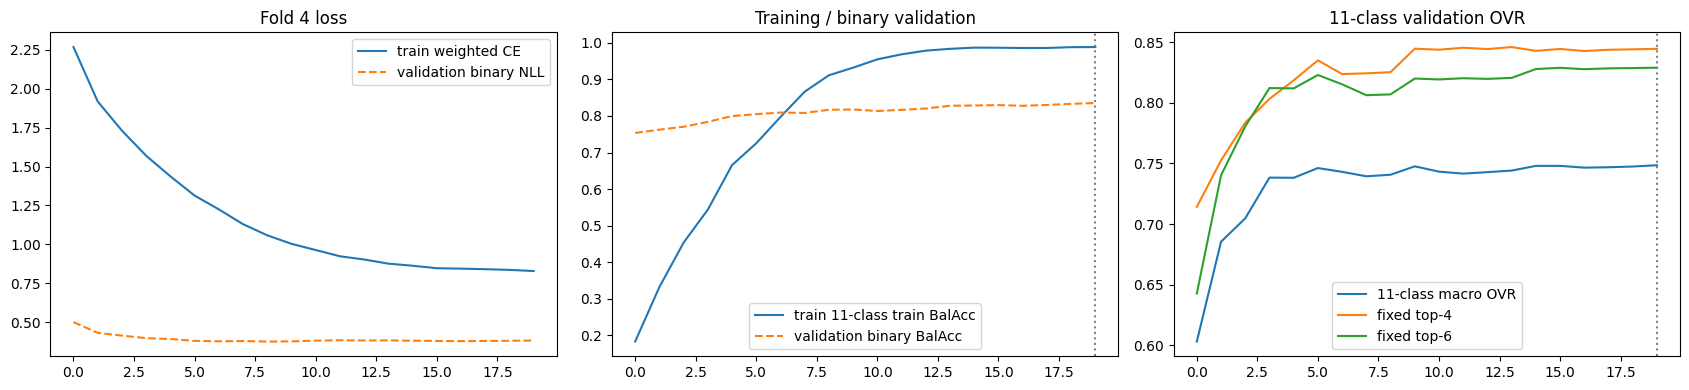

Fold 4 complete. For the next fold, set cfg.fold_to_run to 0 and rerun this fold cell.


In [ ]:
# %% 10 — Run selected fold (one fold per session)
if cfg.fold_to_run < 0 or cfg.fold_to_run >= cfg.n_splits:
    raise IndexError(f'fold_to_run must be in the range 0 to {cfg.n_splits - 1}.')

diagnosis_counts = trainval_lesions['class_label'].value_counts()
if diagnosis_counts.min() < 2:
    raise ValueError('At least one diagnosis has fewer than two train+val lesions; reduce folds or revise the split.')
if diagnosis_counts.min() < cfg.n_splits:
    print('NOTE: some rare diagnoses have fewer lesions than the fold count; a validation fold may omit a diagnosis.')

# Keep the same fold-fitted imputation/scaling implementation if this cell is rerun out of order.
if 'MetadataPreprocessor' not in globals():
    class MetadataPreprocessor:
        """Fits age imputation/scaling and site IDs on this fold's training lesions only."""
        def __init__(self):
            self.fitted = False
            self.age_median = None
            self.age_mean = None
            self.age_std = None
            self.site_vocab = {}

        def fit(self, samples):
            ages = samples['age_approx'].to_numpy(dtype=np.float32)
            finite_ages = ages[np.isfinite(ages)]
            if finite_ages.size == 0:
                raise ValueError('No non-missing age values found in this fold training set.')
            self.age_median = float(np.median(finite_ages))
            ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
            self.age_mean = float(np.mean(ages))
            age_std = float(np.std(ages))
            self.age_std = age_std if age_std > 1e-6 else 1.0
            categories = sorted(set(samples['site'].fillna('Unknown').astype(str).tolist()))
            if 'Unknown' not in categories:
                categories.append('Unknown')
            self.site_vocab = {val: idx for idx, val in enumerate(categories)}
            self.fitted = True
            return self

        @property
        def num_site_categories(self):
            return len(self.site_vocab)

        def transform(self, samples):
            ages = samples['age_approx'].to_numpy(dtype=np.float32)
            ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
            ages = ((ages - self.age_mean) / self.age_std).astype(np.float32)
            sites = samples['site'].fillna('Unknown').astype(str).tolist()
            site_ids = np.asarray([self.site_vocab.get(val, self.site_vocab.get('Unknown', 0)) for val in sites], dtype=np.int64)
            return ages, site_ids

        def state_dict(self):
            return {'age_median': self.age_median, 'age_mean': self.age_mean,
                    'age_std': self.age_std, 'site_vocab': self.site_vocab}

        @classmethod
        def from_state_dict(cls, state):
            obj = cls()
            obj.age_median = float(state['age_median'])
            obj.age_mean = float(state['age_mean'])
            obj.age_std = float(state['age_std'])
            obj.site_vocab = state['site_vocab']
            obj.fitted = True
            return obj

if 'PairedLesionDataset' not in globals():
    class PairedLesionDataset(Dataset):
        def __init__(self, samples, derm_transform, clinical_transform, metadata_preprocessor):
            self.derm_paths = samples['derm_cache_path'].tolist()
            self.clinical_paths = samples['clinical_cache_path'].tolist()
            self.labels = samples['label'].astype(int).tolist()
            self.derm_transform = derm_transform
            self.clinical_transform = clinical_transform
            self.ages, self.site_ids = metadata_preprocessor.transform(samples)

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, index):
            with Image.open(self.derm_paths[index]) as image:
                derm = self.derm_transform(image.convert('RGB'))
            with Image.open(self.clinical_paths[index]) as image:
                clinical = self.clinical_transform(image.convert('RGB'))
            age = torch.tensor(self.ages[index], dtype=torch.float32)
            site = torch.tensor(self.site_ids[index], dtype=torch.long)
            label = torch.tensor(self.labels[index], dtype=torch.long)
            return derm, clinical, age, site, label

fold_stratify_col = 'class_label'
skf = StratifiedKFold(n_splits=cfg.n_splits, shuffle=True, random_state=cfg.seed)
fold_splits = list(skf.split(trainval_lesions, trainval_lesions[fold_stratify_col]))
train_indices, val_indices = fold_splits[cfg.fold_to_run]
train_lesions = trainval_lesions.iloc[train_indices].reset_index(drop=True)
val_lesions = trainval_lesions.iloc[val_indices].reset_index(drop=True)
assert set(train_lesions['lesion_id']).isdisjoint(set(val_lesions['lesion_id']))

train_samples = build_sample_table(train_lesions, 'train')
val_samples = build_sample_table(val_lesions, 'val')
print(f'Fold {cfg.fold_to_run}: {len(train_samples)} paired training lesions | {len(val_samples)} validation lesions')

(model, history, best_bal, best_epoch, best_path,
 metadata_preprocessor, metadata_preprocessor_path) = train_one_fold(
    train_samples, val_samples, cfg.fold_to_run
)

val_probs_11, val_y = predict_probs_tta(
    model, val_samples, metadata_preprocessor, label_col='binary_label'
)
val_probs = aggregate_11class_probs_to_binary(val_probs_11)
threshold_weights, tuned_bal = tune_thresholds(val_probs, val_y)
plain_bal = balanced_accuracy_score(val_y, val_probs.argmax(1))
print(f'Fold {cfg.fold_to_run} validation binary BalAcc: plain={plain_bal:.4f} | tuned={tuned_bal:.4f}')
print('Validation threshold weights:', dict(zip(BINARY_CLASSES, np.round(threshold_weights, 3))))
print('Note: tuned validation BA is a calibration score on the same validation fold; use held-out TEST for final calibrated evaluation.')
report_binary(val_y, (val_probs * threshold_weights).argmax(1), f'Fold {cfg.fold_to_run} validation — tuned')

np.savez(
    os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz'),
    probs=val_probs, probs_11=val_probs_11, y=val_y,
    y_11=val_samples['label'].to_numpy(dtype=np.int64),
    thresholds=threshold_weights,
)
summary = {
    'fold': int(cfg.fold_to_run),
    'best_epoch': int(best_epoch),
    'val_bal_argmax': float(plain_bal),
    'val_bal_tuned': float(tuned_bal),
    'thresholds': threshold_weights.tolist(),
    'path': best_path,
    'metadata_preprocessor_path': metadata_preprocessor_path,
    'train_stratify': fold_stratify_col,
    'train_lesions': int(len(train_lesions)),
    'val_lesions': int(len(val_lesions)),
    'architecture': 'shared_convnextv2_dual_image_plus_age_site_metadata_fusion',
    'input_size': int(cfg.img_size),
    'backbone': cfg.backbone,
    'metadata_features': ['age_approx', 'site'],
    'regularization': {'dropout': cfg.dropout, 'label_smoothing': cfg.label_smoothing,
                       'weight_decay': cfg.weight_decay,
                       'binary_group_balance_strength': cfg.binary_group_balance_strength},
    'fixed_top4_classes': FIXED_TOP4_CLASSES,
    'fixed_top6_classes': FIXED_TOP6_CLASSES,
    'age_column_in_csv': AGE_META_COL,
    'site_column_in_csv': SITE_META_COL,
    'site_vocabulary_size_including_unknown': metadata_preprocessor.num_site_categories,
}
with open(os.path.join(MODEL_DIR, f'fold{cfg.fold_to_run}_summary.json'), 'w') as file:
    json.dump(summary, file, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(history['train_loss'], label='train weighted CE')
axes[0].plot(history['val_binary_nll'], '--', label='validation binary NLL')
axes[0].legend(); axes[0].set_title(f'Fold {cfg.fold_to_run} loss')
axes[1].plot(history['train_bal_acc_11'], label='train 11-class train BalAcc')
axes[1].plot(history['val_bal_acc_binary'], '--', label='validation binary BalAcc')
axes[1].axvline(best_epoch, color='gray', linestyle=':')
axes[1].legend(); axes[1].set_title('Training / binary validation')
axes[2].plot(history['val_11_macro_ovr'], label='11-class macro OVR')
axes[2].plot(history['val_11_fixed_top4'], label='fixed top-4')
axes[2].plot(history['val_11_fixed_top6'], label='fixed top-6')
axes[2].axvline(best_epoch, color='gray', linestyle=':')
axes[2].legend(); axes[2].set_title('11-class validation OVR')
plt.tight_layout(); plt.show()
print(f'Fold {cfg.fold_to_run} complete. For the next fold, set cfg.fold_to_run to '
      f'{(cfg.fold_to_run + 1) % cfg.n_splits} and rerun this fold cell.')

In [ ]:
import glob
import os

model_dir = '/content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2'
# Find all files with 'fold3' in their name
fold3_files = glob.glob(os.path.join(model_dir, '*fold3*'))

if fold3_files:
    print(f"Found {len(fold3_files)} files related to fold 3. Removing them...")
    for filepath in fold3_files:
        try:
            os.remove(filepath)
            print(f"Removed: {os.path.basename(filepath)}")
        except Exception as e:
            print(f"Failed to remove {os.path.basename(filepath)}: {e}")
else:
    print("No fold 3 files found in the directory.")

Found 6 files related to fold 3. Removing them...
Removed: oof_fold3.npz
Removed: MILK10k_image_metadata_fold3_hist.json
Removed: MILK10k_image_metadata_fold3_last.pt
Removed: fold3_summary.json
Removed: MILK10k_image_metadata_fold3_best.pt
Removed: MILK10k_image_metadata_fold3_preprocessor.json


In [ ]:
import os
import zipfile
from google.colab import files

# Define paths
source_dir = '/content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2'
zip_path = '/content/fold1_fusion.zip'

print(f"Zipping files from {source_dir}...")
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(source_dir):
        for file in files_list:
            file_path = os.path.join(root, file)
            # Archive path should be relative to the source directory
            arcname = os.path.relpath(file_path, source_dir)
            zipf.write(file_path, arcname)

print(f"Successfully created zip file at {zip_path}")
print("Triggering download...")
files.download(zip_path)

Zipping files from /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2...
Successfully created zip file at /content/fold1_fusion.zip
Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Final Testing

In [ ]:
!gdown --id 1wFkXN-7Lx4NNae5m4Kwmosb-AfJBhL0g

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1wFkXN-7Lx4NNae5m4Kwmosb-AfJBhL0g
From (redirected): https://drive.google.com/uc?id=1wFkXN-7Lx4NNae5m4Kwmosb-AfJBhL0g&confirm=t&uuid=16591eb6-68f4-4365-a901-e7babae309bb
To: /content/fold4_fusion.zip
100% 2.70G/2.70G [00:53<00:00, 50.7MB/s]


In [ ]:
!unzip -q /content/fold4_fusion.zip

Archive:  /content/fold4_fusion.zip
   creating: fold4_fusion/
  inflating: fold4_fusion/fold0_summary.json  
  inflating: fold4_fusion/fold1_summary.json  
  inflating: fold4_fusion/fold2_summary.json  
  inflating: fold4_fusion/fold3_summary.json  
  inflating: fold4_fusion/fold4_summary.json  
  inflating: fold4_fusion/MILK10k_image_metadata_fold0_best.pt  
  inflating: fold4_fusion/MILK10k_image_metadata_fold0_hist.json  
  inflating: fold4_fusion/MILK10k_image_metadata_fold0_last.pt  
  inflating: fold4_fusion/MILK10k_image_metadata_fold0_preprocessor.json  
  inflating: fold4_fusion/MILK10k_image_metadata_fold1_best.pt  
  inflating: fold4_fusion/MILK10k_image_metadata_fold1_hist.json  
  inflating: fold4_fusion/MILK10k_image_metadata_fold1_last.pt  
  inflating: fold4_fusion/MILK10k_image_metadata_fold1_preprocessor.json  
  inflating: fold4_fusion/MILK10k_image_metadata_fold2_best.pt  
  inflating: fold4_fusion/MILK10k_image_metadata_fold2_hist.json  
  inflating: fold4_fusion/

In [ ]:
import os
import shutil

source_dir = '/content/fold4_fusion'
dest_dir = '/content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2'

os.makedirs(dest_dir, exist_ok=True)

if os.path.exists(source_dir):
    files = os.listdir(source_dir)
    for file_name in files:
        source_path = os.path.join(source_dir, file_name)
        dest_path = os.path.join(dest_dir, file_name)
        if os.path.isfile(source_path):
            shutil.move(source_path, dest_path)
            print(f"Moved: {file_name}")
    print("All files have been successfully moved.")
else:
    print(f"Source directory {source_dir} does not exist.")

Moved: oof_fold3.npz
Moved: MILK10k_image_metadata_fold3_best.pt
Moved: MILK10k_image_metadata_fold3_last.pt
Moved: fold0_summary.json
Moved: fold1_summary.json
Moved: MILK10k_image_metadata_fold1_best.pt
Moved: MILK10k_image_metadata_fold1_last.pt
Moved: MILK10k_image_metadata_fold1_preprocessor.json
Moved: oof_fold4.npz
Moved: MILK10k_image_metadata_fold2_hist.json
Moved: MILK10k_image_metadata_fold2_best.pt
Moved: MILK10k_image_metadata_fold4_preprocessor.json
Moved: MILK10k_image_metadata_fold0_preprocessor.json
Moved: MILK10k_image_metadata_fold3_hist.json
Moved: oof_fold0.npz
Moved: oof_fold2.npz
Moved: MILK10k_image_metadata_fold3_preprocessor.json
Moved: MILK10k_image_metadata_fold0_best.pt
Moved: MILK10k_image_metadata_fold4_hist.json
Moved: oof_combined_primary_fusion.npz
Moved: MILK10k_image_metadata_fold1_hist.json
Moved: oof_fold1.npz
Moved: fold2_summary.json
Moved: MILK10k_image_metadata_fold4_best.pt
Moved: MILK10k_image_metadata_fold0_hist.json
Moved: MILK10k_image_met

In [ ]:
# %% 11 — Combine completed folds (primary Metadata + CNN Fusion OOF evaluation)
oof_files = sorted(glob.glob(os.path.join(MODEL_DIR, 'oof_fold*.npz')))
print(f'Found {len(oof_files)} completed OOF fold file(s): {[os.path.basename(path) for path in oof_files]}')
if oof_files:
    saved_folds = [np.load(path) for path in oof_files]
    oof_probs = np.concatenate([item['probs'] for item in saved_folds], axis=0)
    oof_y = np.concatenate([item['y'] for item in saved_folds], axis=0)
    oof_probs_11 = np.concatenate([item['probs_11'] for item in saved_folds], axis=0)
    oof_y_11 = np.concatenate([item['y_11'] for item in saved_folds], axis=0)

    report_binary(oof_y, oof_probs.argmax(1), f'OOF binary evaluation ({len(oof_files)} folds; raw argmax)')
    oof_class_scores, oof_macro_11, oof_top4_11, oof_top6_11 = compute_11class_ovr_metrics(oof_probs_11, oof_y_11)
    print('\n=== OOF 11-class OVR results — fixed groups ===')
    for class_name in CLASSES:
        value = oof_class_scores[class_name]
        print(f'{class_name:<8}: {value:.4f}' if np.isfinite(value) else f'{class_name:<8}: unavailable (class absent)')
    print(f'11-class macro OVR: {oof_macro_11:.4f}')
    print(f'Fixed top-4 {FIXED_TOP4_CLASSES}: {oof_top4_11:.4f}')
    print(f'Fixed top-6 {FIXED_TOP6_CLASSES}: {oof_top6_11:.4f}')

    # Report per-fold validation calibration figures from the fold summaries.
    for path in oof_files:
        fold_match = re.search(r'oof_fold(\d+)\.npz$', os.path.basename(path))
        if fold_match:
            summary_path = os.path.join(MODEL_DIR, f'fold{fold_match.group(1)}_summary.json')
            if os.path.exists(summary_path):
                with open(summary_path) as f:
                    summary = json.load(f)
                print(f"Fold {summary['fold']}: raw BA={summary['val_bal_argmax']:.4f} | "
                      f"validation-calibrated BA={summary['val_bal_tuned']:.4f} | "
                      f"best epoch={summary['best_epoch'] + 1}")

    # Deliberately save raw OOF predictions only. Each fold's own tuned threshold was fit
    # on that same fold's labels, so averaging those tuned scores is not unbiased OOF.
    np.savez(os.path.join(MODEL_DIR, 'oof_combined_primary_fusion.npz'),
             probs=oof_probs, y=oof_y, probs_11=oof_probs_11, y_11=oof_y_11)
else:
    print('No OOF files found. Complete at least one training fold first.')


Found 5 completed OOF fold file(s): ['oof_fold0.npz', 'oof_fold1.npz', 'oof_fold2.npz', 'oof_fold3.npz', 'oof_fold4.npz']

=== OOF binary evaluation (5 folds; raw argmax) === Binary Bal-Acc 0.8368 | 95% CI [0.8244, 0.8497] | n=4716
              precision    recall  f1-score   support

      Benign      0.773     0.762     0.767      1334
   Malignant      0.907     0.912     0.909      3382

    accuracy                          0.869      4716
   macro avg      0.840     0.837     0.838      4716
weighted avg      0.869     0.869     0.869      4716

Confusion matrix (rows=true; Benign, Malignant):
[[1016  318]
 [ 298 3084]]

=== OOF 11-class OVR results — fixed groups ===
AKIEC   : 0.7047
BCC     : 0.8786
BEN_OTH : 0.5854
BKL     : 0.7230
DF      : 0.7212
INF     : 0.6200
MAL_OTH : 0.4998
MEL     : 0.7622
NV      : 0.8892
SCCKA   : 0.8387
VASC    : 0.8782
11-class macro OVR: 0.7364
Fixed top-4 ['NV', 'DF', 'BCC', 'SCCKA']: 0.8319
Fixed top-6 ['NV', 'DF', 'BCC', 'SCCKA', 'INF', 'VASC

In [ ]:
# %% 12 — Held-out TEST ensemble (primary Metadata + CNN Fusion; run after all five folds)
summary_files = sorted(glob.glob(os.path.join(MODEL_DIR, 'fold*_summary.json')))
print(f'Found {len(summary_files)} completed fold summary file(s).')
if len(summary_files) < cfg.n_splits:
    raise RuntimeError(f'Complete all {cfg.n_splits} folds before final test evaluation; found {len(summary_files)}.')

# Test samples were excluded at lesion level before any fold training.
test_samples = build_sample_table(test_lesions, 'test')
assert len(test_samples) == len(test_lesions), (
    f'Only {len(test_samples)} of {len(test_lesions)} test lesions have complete image pairs.'
)
test_probs_11_ensemble = np.zeros((len(test_samples), NUM_CLASSES), dtype=np.float32)
fold_thresholds = []

for summary_path in summary_files:
    with open(summary_path) as file:
        summary = json.load(file)
    model_path = summary['path']
    metadata_path = summary['metadata_preprocessor_path']
    with open(metadata_path) as file:
        metadata_state = json.load(file)
    fold_metadata_preprocessor = MetadataPreprocessor.from_state_dict(metadata_state)

    print('Ensembling:', os.path.basename(model_path))
    fold_model = DualImageMetadataConvNeXtV2(
        NUM_CLASSES,
        num_site_categories=fold_metadata_preprocessor.num_site_categories,
        model_name=cfg.backbone,
        pretrained=False,
    ).to(DEVICE)
    fold_model.load_state_dict(torch.load(model_path, map_location=DEVICE, weights_only=True))
    fold_model.eval()
    fold_probs_11, _ = predict_probs_tta(
        fold_model, test_samples, fold_metadata_preprocessor, label_col='label'
    )
    test_probs_11_ensemble += fold_probs_11
    fold_thresholds.append(np.asarray(summary['thresholds'], dtype=np.float32))
    del fold_model
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

test_probs_11_ensemble /= len(summary_files)
test_probs_binary_ensemble = aggregate_11class_probs_to_binary(test_probs_11_ensemble)
median_thresholds = np.median(np.stack(fold_thresholds), axis=0)
y_test_binary = test_samples['binary_label'].to_numpy(dtype=np.int64)
y_test_11 = test_samples['label'].to_numpy(dtype=np.int64)

print('Median validation-derived threshold weights:', dict(zip(BINARY_CLASSES, np.round(median_thresholds, 3))))
print('Thresholds were fitted on fold validation sets; held-out test labels are not used for calibration.')
report_binary(y_test_binary, test_probs_binary_ensemble.argmax(1), 'TEST ensemble — plain argmax')
report_binary(y_test_binary, (test_probs_binary_ensemble * median_thresholds).argmax(1),
              'TEST ensemble — validation-tuned weights')

np.savez(
    os.path.join(MODEL_DIR, 'test_ensemble_image_metadata.npz'),
    probs_binary=test_probs_binary_ensemble,
    probs_11=test_probs_11_ensemble,
    y_binary=y_test_binary,
    y_11=y_test_11,
    thresholds=median_thresholds,
)
print('Saved image + age/site metadata test ensemble predictions.')

Found 5 completed fold summary file(s).
Ensembling: MILK10k_image_metadata_fold0_best.pt
Ensembling: MILK10k_image_metadata_fold1_best.pt
Ensembling: MILK10k_image_metadata_fold2_best.pt
Ensembling: MILK10k_image_metadata_fold3_best.pt
Ensembling: MILK10k_image_metadata_fold4_best.pt
Median validation-derived threshold weights: {'Benign': np.float32(0.588), 'Malignant': np.float32(0.412)}
Thresholds were fitted on fold validation sets; held-out test labels are not used for calibration.

=== TEST ensemble — plain argmax === Binary Bal-Acc 0.8344 | 95% CI [0.7945, 0.8713] | n=524
              precision    recall  f1-score   support

      Benign      0.793     0.745     0.768       149
   Malignant      0.901     0.923     0.912       375

    accuracy                          0.872       524
   macro avg      0.847     0.834     0.840       524
weighted avg      0.870     0.872     0.871       524

Confusion matrix (rows=true; Benign, Malignant):
[[111  38]
 [ 29 346]]

=== TEST ensemb

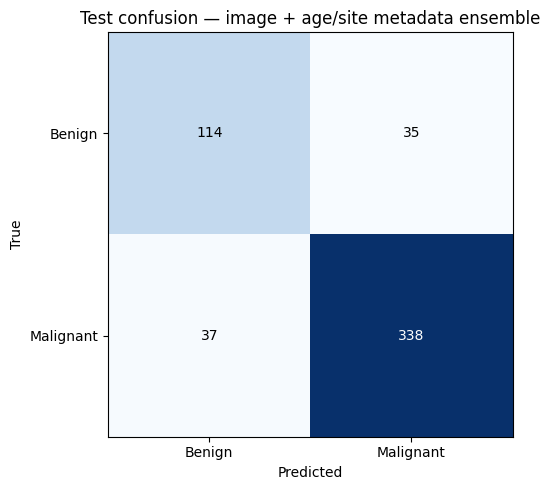

Errors: 72/524 | mean confidence margin on errors: 0.448 | correct: 0.650


In [ ]:
# %% 13 — Binary test error analysis
saved = np.load(os.path.join(MODEL_DIR, 'test_ensemble_image_metadata.npz'))
test_probs_binary = saved['probs_binary']
thresholds = saved['thresholds']
y_true = saved['y_binary'].astype(int)
y_pred = (test_probs_binary * thresholds).argmax(1)

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(BINARY_CLASSES)))
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(np.arange(2), BINARY_CLASSES)
ax.set_yticks(np.arange(2), BINARY_CLASSES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Test confusion — image + age/site metadata ensemble')
for row in range(2):
    for col in range(2):
        ax.text(col, row, cm[row, col], ha='center', va='center',
                color='white' if cm[row, col] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.show()

sorted_probs = np.sort(test_probs_binary, axis=1)
margin = sorted_probs[:, -1] - sorted_probs[:, -2]
incorrect = y_pred != y_true
print(f'Errors: {incorrect.sum()}/{len(y_true)} | '
      f'mean confidence margin on errors: {margin[incorrect].mean() if incorrect.any() else float("nan"):.3f} | '
      f'correct: {margin[~incorrect].mean() if (~incorrect).any() else float("nan"):.3f}')

=== One-vs-Rest Balanced Accuracy per Class (Primary Metadata + CNN Fusion) ===

AKIEC    : 0.7076
BCC      : 0.8791
BEN_OTH  : 0.4981
BKL      : 0.7246
DF       : 0.9000
INF      : 0.7000
MAL_OTH  : 0.5000
MEL      : 0.7552
NV       : 0.9155
SCCKA    : 0.8324
VASC     : 0.7961

Macro one-vs-rest BalAcc (11 classes): 74.62%
Fixed top-4 ['NV', 'DF', 'BCC', 'SCCKA'] OVR BalAcc average: 88.18%
Fixed top-6 ['NV', 'DF', 'BCC', 'SCCKA', 'INF', 'VASC'] OVR BalAcc average: 83.72%


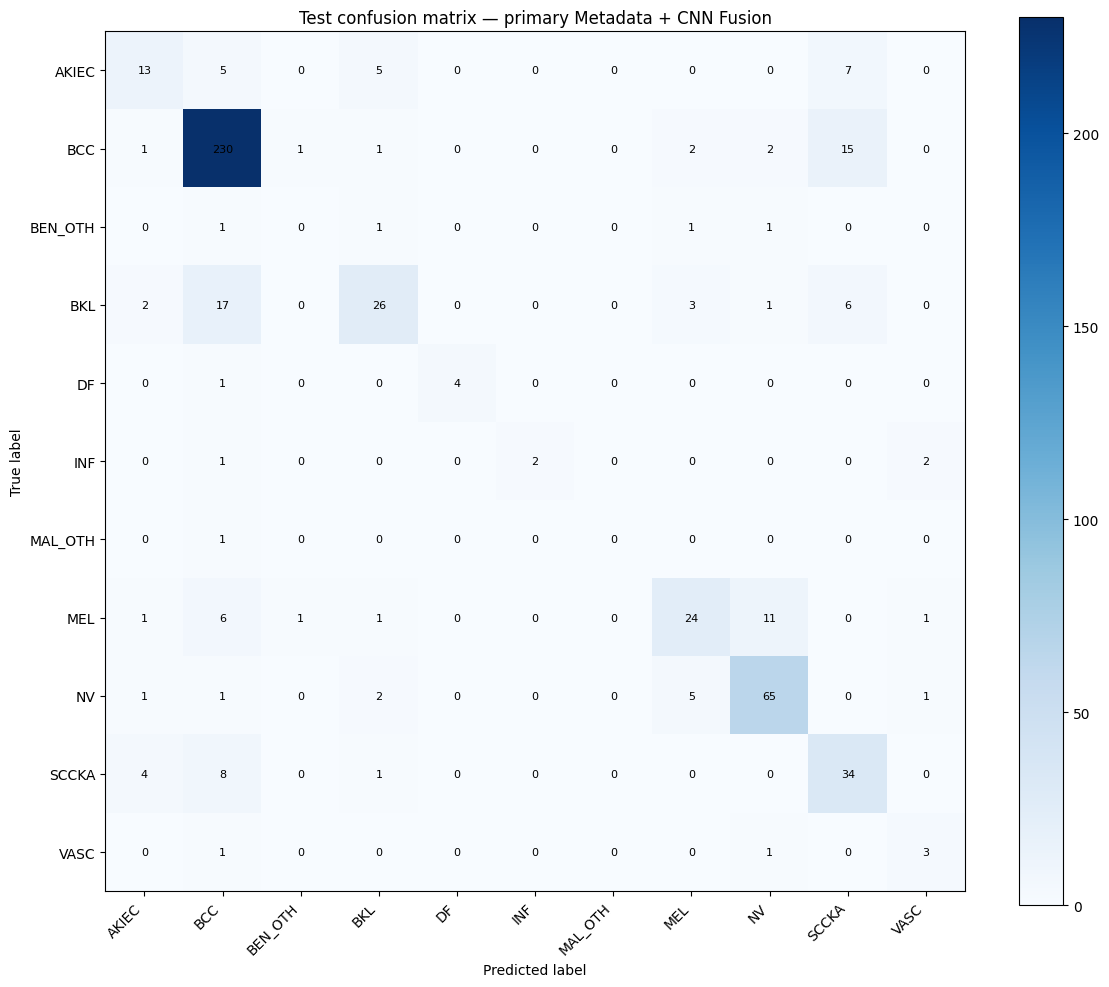

In [ ]:
# %% 14 — Per-diagnosis one-vs-rest Balanced Accuracy (primary Metadata + CNN Fusion)
saved = np.load(os.path.join(MODEL_DIR, 'test_ensemble_image_metadata.npz'))
probs_11 = saved['probs_11']
y_true_11 = saved['y_11'].astype(int)
y_pred_11 = probs_11.argmax(1)

class_scores, overall_avg, top_4_avg, top_6_avg = compute_11class_ovr_metrics(probs_11, y_true_11)
print('=== One-vs-Rest Balanced Accuracy per Class (Primary Metadata + CNN Fusion) ===\n')
for class_name in CLASSES:
    score = class_scores[class_name]
    print(f'{class_name:<8} : {score:.4f}' if np.isfinite(score)
          else f'{class_name:<8} : unavailable (class absent from test split)')

print(f'\nMacro one-vs-rest BalAcc (11 classes): {overall_avg * 100:.2f}%')
print(f'Fixed top-4 {FIXED_TOP4_CLASSES} OVR BalAcc average: {top_4_avg * 100:.2f}%')
print(f'Fixed top-6 {FIXED_TOP6_CLASSES} OVR BalAcc average: {top_6_avg * 100:.2f}%')

cm_11 = confusion_matrix(y_true_11, y_pred_11, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(cm_11, cmap='Blues')
ax.set_xticks(np.arange(NUM_CLASSES), CLASSES, rotation=45, ha='right')
ax.set_yticks(np.arange(NUM_CLASSES), CLASSES)
ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
ax.set_title('Test confusion matrix — primary Metadata + CNN Fusion')
for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        ax.text(col, row, cm_11[row, col], ha='center', va='center', fontsize=8)
fig.colorbar(ax.images[0], ax=ax); plt.tight_layout(); plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, balanced_accuracy_score

# Load saved test ensemble predictions
saved = np.load(os.path.join(MODEL_DIR, 'test_ensemble_image_metadata.npz'))
test_probs_binary = saved['probs_binary']
test_probs_11 = saved['probs_11']
y_test_binary = saved['y_binary'].astype(int)
y_test_11 = saved['y_11'].astype(int)
thresholds = saved['thresholds']

# Binary Predictions (unweighted and validation-tuned)
y_pred_binary_plain = test_probs_binary.argmax(1)
y_pred_binary_tuned = (test_probs_binary * thresholds).argmax(1)

# Compute standard reports
binary_report_plain = classification_report(y_test_binary, y_pred_binary_plain, target_names=BINARY_CLASSES, output_dict=True)
binary_report_tuned = classification_report(y_test_binary, y_pred_binary_tuned, target_names=BINARY_CLASSES, output_dict=True)

# Compute balanced accuracies
ba_binary_plain = balanced_accuracy_score(y_test_binary, y_pred_binary_plain)
ba_binary_tuned = balanced_accuracy_score(y_test_binary, y_pred_binary_tuned)

# 11-Class OVR Balanced Accuracies
class_scores, macro_11, top4_11, top6_11 = compute_11class_ovr_metrics(test_probs_11, y_test_11)

# Assemble all metrics systematically into a DataFrame
report_rows = []

# 1. Binary Plain Metrics
report_rows.append({"Metric Category": "Binary Plain (Argmax)", "Metric Name": "Balanced Accuracy", "Value": ba_binary_plain})
for cls_name in BINARY_CLASSES:
    for metric in ['precision', 'recall', 'f1-score']:
        val = binary_report_plain[cls_name][metric]
        report_rows.append({"Metric Category": f"Binary Plain - {cls_name}", "Metric Name": metric, "Value": val})

# 2. Binary Tuned Metrics
report_rows.append({"Metric Category": "Binary Tuned (Thresholded)", "Metric Name": "Balanced Accuracy", "Value": ba_binary_tuned})
for cls_name in BINARY_CLASSES:
    for metric in ['precision', 'recall', 'f1-score']:
        val = binary_report_tuned[cls_name][metric]
        report_rows.append({"Metric Category": f"Binary Tuned - {cls_name}", "Metric Name": metric, "Value": val})

# 3. 11-Class OVR Balanced Accuracies
report_rows.append({"Metric Category": "11-Class OVR", "Metric Name": "Macro OVR Average", "Value": macro_11})
report_rows.append({"Metric Category": "11-Class OVR", "Metric Name": "Fixed Top-4 Average", "Value": top4_11})
report_rows.append({"Metric Category": "11-Class OVR", "Metric Name": "Fixed Top-6 Average", "Value": top6_11})
for cls_name in CLASSES:
    report_rows.append({"Metric Category": "11-Class OVR Per-Class", "Metric Name": f"{cls_name} Balanced Accuracy", "Value": class_scores[cls_name]})

# Convert to DataFrame and save as CSV
report_df = pd.DataFrame(report_rows)
csv_path = os.path.join(MODEL_DIR, 'test_ensemble_final_report.csv')
report_df.to_csv(csv_path, index=False)

print(f"Final test ensemble report successfully compiled and saved to: {csv_path}")
# Display the top part of the generated CSV
print(report_df.head(15))

Final test ensemble report successfully compiled and saved to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2/test_ensemble_final_report.csv
               Metric Category        Metric Name     Value
0        Binary Plain (Argmax)  Balanced Accuracy  0.833817
1        Binary Plain - Benign          precision  0.792857
2        Binary Plain - Benign             recall  0.744966
3        Binary Plain - Benign           f1-score  0.768166
4     Binary Plain - Malignant          precision  0.901042
5     Binary Plain - Malignant             recall  0.922667
6     Binary Plain - Malignant           f1-score  0.911726
7   Binary Tuned (Thresholded)  Balanced Accuracy  0.833217
8        Binary Tuned - Benign          precision  0.754967
9        Binary Tuned - Benign             recall  0.765101
10       Binary Tuned - Benign           f1-score  0.760000
11    Binary Tuned - Malignant          precision  0.906166
12    Binary Tuned - Malign

In [ ]:
import os
import pandas as pd

# Prepare the 11-class metrics list
ovr_rows = []

# 1. Macro-level averages
ovr_rows.append({
    "Metric Type": "Summary Average",
    "Class/Subset": "Macro 11-Class OVR",
    "Balanced Accuracy": macro_11
})
ovr_rows.append({
    "Metric Type": "Summary Average",
    "Class/Subset": f"Fixed Top-4 {FIXED_TOP4_CLASSES}",
    "Balanced Accuracy": top4_11
})
ovr_rows.append({
    "Metric Type": "Summary Average",
    "Class/Subset": f"Fixed Top-6 {FIXED_TOP6_CLASSES}",
    "Balanced Accuracy": top6_11
})

# 2. Individual Class Scores
for cls_name in CLASSES:
    ovr_rows.append({
        "Metric Type": "Individual Class OVR",
        "Class/Subset": cls_name,
        "Balanced Accuracy": class_scores[cls_name]
    })

# Convert to DataFrame and save
ovr_report_df = pd.DataFrame(ovr_rows)
ovr_csv_path = os.path.join(MODEL_DIR, 'test_ensemble_11class_ovr_report.csv')
ovr_report_df.to_csv(ovr_csv_path, index=False)

print(f"Successfully saved 11-class OVR report to: {ovr_csv_path}")
display(ovr_report_df)

Successfully saved 11-class OVR report to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2/test_ensemble_11class_ovr_report.csv


,Metric Type,Class/Subset,Balanced Accuracy
0,Summary Average,Macro 11-Class OVR,0.746238
1,Summary Average,"Fixed Top-4 ['NV', 'DF', 'BCC', 'SCCKA']",0.881753
2,Summary Average,"Fixed Top-6 ['NV', 'DF', 'BCC', 'SCCKA', 'INF'...",0.837193
3,Individual Class OVR,AKIEC,0.707557
4,Individual Class OVR,BCC,0.879143
5,Individual Class OVR,BEN_OTH,0.498077
6,Individual Class OVR,BKL,0.724637
7,Individual Class OVR,DF,0.900000
8,Individual Class OVR,INF,0.700000
9,Individual Class OVR,MAL_OTH,0.500000


In [ ]:
import os
import pandas as pd

# Compile the Out-of-Fold (OOF) 11-class OVR metrics
oof_ovr_rows = []

# 1. Macro-level averages for OOF
oof_ovr_rows.append({
    "Metric Type": "OOF Summary Average",
    "Class/Subset": "Macro 11-Class OVR",
    "Balanced Accuracy": oof_macro_11
})
oof_ovr_rows.append({
    "Metric Type": "OOF Summary Average",
    "Class/Subset": f"Fixed Top-4 {FIXED_TOP4_CLASSES}",
    "Balanced Accuracy": oof_top4_11
})
oof_ovr_rows.append({
    "Metric Type": "OOF Summary Average",
    "Class/Subset": f"Fixed Top-6 {FIXED_TOP6_CLASSES}",
    "Balanced Accuracy": oof_top6_11
})

# 2. Individual Class OOF Scores
for cls_name in CLASSES:
    oof_ovr_rows.append({
        "Metric Type": "OOF Individual Class OVR",
        "Class/Subset": cls_name,
        "Balanced Accuracy": oof_class_scores[cls_name]
    })

# Convert to DataFrame and save to CSV
oof_ovr_report_df = pd.DataFrame(oof_ovr_rows)
oof_csv_path = os.path.join(MODEL_DIR, 'oof_ensemble_11class_ovr_report.csv')
oof_ovr_report_df.to_csv(oof_csv_path, index=False)

print(f"Successfully saved OOF 11-class OVR report to: {oof_csv_path}")
display(oof_ovr_report_df)

Successfully saved OOF 11-class OVR report to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_11class_binary_eval_320_reg_v2/oof_ensemble_11class_ovr_report.csv


,Metric Type,Class/Subset,Balanced Accuracy
0,OOF Summary Average,Macro 11-Class OVR,0.736437
1,OOF Summary Average,"Fixed Top-4 ['NV', 'DF', 'BCC', 'SCCKA']",0.831917
2,OOF Summary Average,"Fixed Top-6 ['NV', 'DF', 'BCC', 'SCCKA', 'INF'...",0.804302
3,OOF Individual Class OVR,AKIEC,0.704669
4,OOF Individual Class OVR,BCC,0.878599
5,OOF Individual Class OVR,BEN_OTH,0.585361
6,OOF Individual Class OVR,BKL,0.722974
7,OOF Individual Class OVR,DF,0.721155
8,OOF Individual Class OVR,INF,0.619974
9,OOF Individual Class OVR,MAL_OTH,0.499788
